import library

In [3]:
import pandas as pd
import numpy as np

read the data

In [2]:
df = pd.read_csv("C:\\Users\\Asus\\Desktop\\data for project coach you\\ai4i2020.csv")


In [4]:
import numpy as np
import pandas as pd

# =========================================================
# مكان حفظ الداتا
# غيّر هذا المسار للمكان اللي بدك إياه
# =========================================================

save_path = r"C:\Users\Asus\Desktop\ai4i2020_dirty.csv"


# =========================================================
# قراءة الداتا الأصلية
# =========================================================


rng = np.random.default_rng(42)
n = len(df)


# =========================================================
# 1) إضافة Null Values
# =========================================================

numeric_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

for col in numeric_cols:
    null_indices = rng.choice(n, int(n * 0.08), replace=False)
    df.loc[null_indices, col] = np.nan


# =========================================================
# 2) إضافة Outliers
# =========================================================

df.loc[[5, 40, 77], "Air temperature [K]"] = [150, 500, 999]

df.loc[[12, 60, 133], "Process temperature [K]"] = [100, 600, 1000]

df.loc[[200, 500, 800], "Rotational speed [rpm]"] = [
    -100, 50000, 100000
]

df.loc[[300, 600, 900], "Torque [Nm]"] = [
    -50, 500, 1000
]

df.loc[[1000, 2000, 3000], "Tool wear [min]"] = [
    -20, 1000, 5000
]


# =========================================================
# 3) إضافة Duplicates
# =========================================================

duplicates = df.sample(100, random_state=1)

df = pd.concat([df, duplicates], ignore_index=True)

df = df.sample(frac=1, random_state=7).reset_index(drop=True)


# =========================================================
# 4) حفظ الداتا بالمكان المحدد
# =========================================================

df.to_csv(save_path, index=False)


# =========================================================
# 5) التأكد من الحفظ
# =========================================================

print("تم حفظ الداتا بنجاح!")
print("مكان الحفظ:")
print(save_path)

print("\nحجم الداتا:")
print(df.shape)

تم حفظ الداتا بنجاح!
مكان الحفظ:
C:\Users\Asus\Desktop\ai4i2020_dirty.csv

حجم الداتا:
(10200, 14)


Read the failer data

In [4]:
df_1 = pd.read_csv(r"C:\Users\Asus\Desktop\ai4i-predictive-maintenance\Data\not_clean_data.csv")

In [5]:
print(df_1.isnull().sum())
print(df_1.duplicated().sum())


UDI                           0
Product ID                    0
Type                          0
Air temperature [K]        1585
Process temperature [K]    1572
Rotational speed [rpm]     1549
Torque [Nm]                1573
Tool wear [min]            1585
Machine failure               0
TWF                           0
HDF                           0
PWF                           0
OSF                           0
RNF                           0
dtype: int64
147


In [6]:
print(df_1.dtypes)

UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]     float64
Torque [Nm]                float64
Tool wear [min]            float64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object


Detect the outleir

Text(0.5, 1.0, 'Air Temperature Spread')

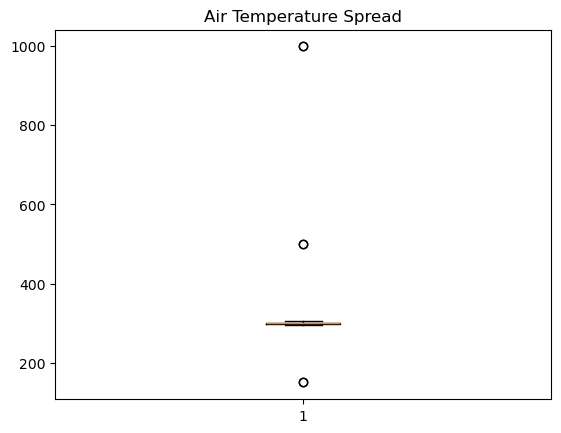

In [19]:
plt.boxplot(df_1["Air temperature [K]"].dropna()) 
plt.title("Air Temperature Spread") 


Text(0.5, 1.0, 'Process Temperature Spread')

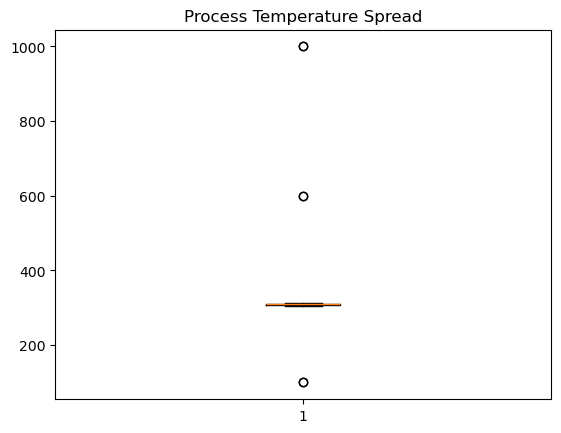

In [20]:
plt.boxplot(df_1["Process temperature [K]"].dropna()) 
plt.title("Process Temperature Spread") 

Text(0.5, 1.0, 'Rotational Speed Spread')

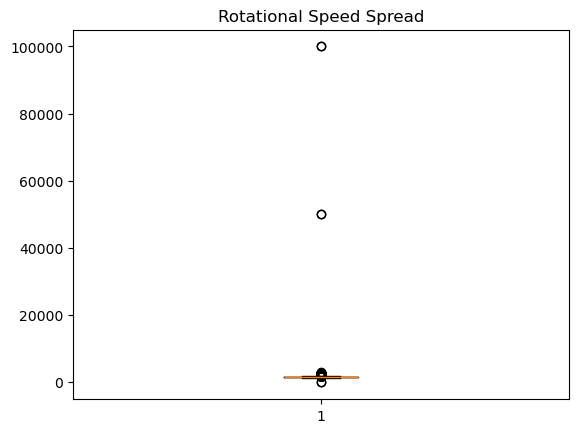

In [21]:
plt.boxplot(df_1["Rotational speed [rpm]"].dropna()) 
plt.title("Rotational Speed Spread") 

Text(0.5, 1.0, 'Torque Spread')

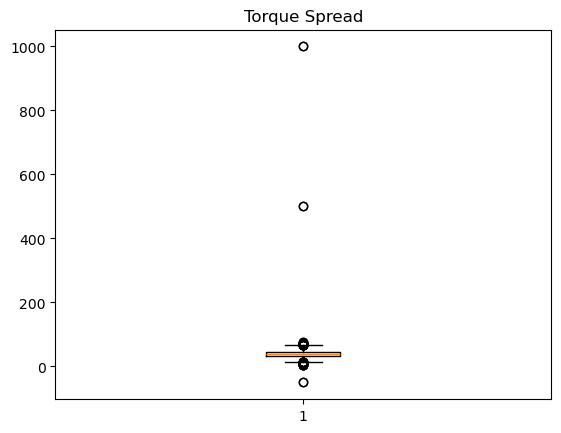

In [22]:
plt.boxplot(df_1["Torque [Nm]"].dropna()) 
plt.title("Torque Spread") 

Text(0.5, 1.0, 'Tool Wear Spread')

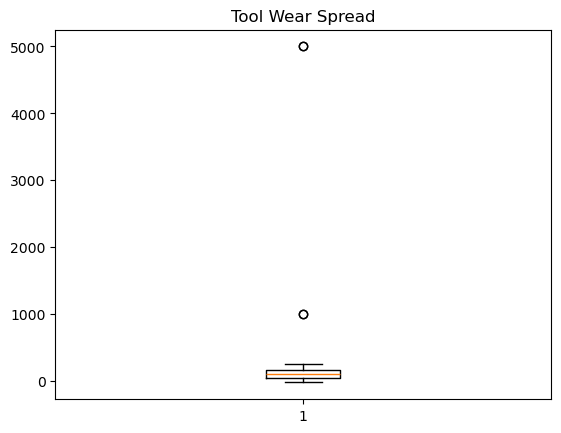

In [23]:
plt.boxplot(df_1["Tool wear [min]"].dropna()) 
plt.title("Tool Wear Spread") 

In [9]:
q1 = df_1["Rotational speed [rpm]"].quantile(0.25)
q3 = df_1["Rotational speed [rpm]"].quantile(0.75)
iqr = q3 - q1
outliers = df_1[(df_1["Rotational speed [rpm]"] < q1 - 1.5 * iqr) | (df_1["Rotational speed [rpm]"] > q3 + 1.5 * iqr)]
print(len(outliers))

370


In [14]:
q1 = df_1["Air temperature [K]"].quantile(0.25)
q3 = df_1["Air temperature [K]"].quantile(0.75)
iqr = q3 - q1
outliers = df_1[(df_1["Air temperature [K]"] < q1 - 1.5 * iqr) | (df_1["Air temperature [K]"] > q3 + 1.5 * iqr)]
print(len(outliers))

6


In [15]:
q1 = df_1["Process temperature [K]"].quantile(0.25)
q3 = df_1["Process temperature [K]"].quantile(0.75)
iqr = q3 - q1
outliers = df_1[(df_1["Process temperature [K]"] < q1 - 1.5 * iqr) | (df_1["Process temperature [K]"] > q3 + 1.5 * iqr)]
print(len(outliers))

6


In [16]:
q1 = df_1["Torque [Nm]"].quantile(0.25)
q3 = df_1["Torque [Nm]"].quantile(0.75)
iqr = q3 - q1
outliers = df_1[(df_1["Torque [Nm]"] < q1 - 1.5 * iqr) | (df_1["Torque [Nm]"] > q3 + 1.5 * iqr)]
print(len(outliers))

69


In [17]:
q1 = df_1["Tool wear [min]"].quantile(0.25)
q3 = df_1["Tool wear [min]"].quantile(0.75)
iqr = q3 - q1
outliers = df_1[(df_1["Tool wear [min]"] < q1 - 1.5 * iqr) | (df_1["Tool wear [min]"] > q3 + 1.5 * iqr)]
print(len(outliers))

4
